# 한국어 Kiwi와 BM25

**이 노트북에서 할 일**

1. 한국어 한 문장을 공백과 형태소로 나눈 결과를 견줍니다.
2. 문서 12개와 질문 8개에 같은 정책으로 검색 낱말을 만듭니다.
3. BM25 점수로 상위 세 문서를 받아 오고 드문 낱말의 몫을 봅니다.
4. 정책만 공백 분리로 바꿔 질문 여덟 개의 재현율을 견줍니다.

**준비물** — 이 절은 OpenAI API 키와 데이터베이스를 쓰지 않습니다.
임베딩 요청도 보내지 않으므로 드는 비용이 없습니다.
읽는 자료는 01~03절과 같은 문서 파일과 질문 파일 두 개입니다.
실행 시간은 30초 안팎이고 첫 셀의 설치가 가장 오래 걸립니다.

**데이터** — 두 파일 모두 실습 묶음에 들어 있습니다.

- 문서 `labs/part3/ch12-retrieval-tuning/data/core-documents.json`(12개)
- 질문 `labs/part3/ch12-retrieval-tuning/data/core-queries.json`(8개)

**강의와 실습 범위** — 강의 시간에는 3~4절과 6~7절, 9~10절을 읽습니다.
형태소와 품사 표시를 보고 검색 낱말을 만드는 자리입니다.
이어서 BM25 모델을 만들고 드문 낱말을 세어 봅니다.
9~10절은 실행 1과 값 바꿔 보기입니다.
2절과 5절, 8절, 11~12절은 함께 실행하고 실습 시간에 다시 읽습니다.

**기준 버전** — 첫 셀에서 kiwipiepy 0.23.2와 rank-bm25 0.2.2를 설치합니다.
형태소 사전은 설치할 때 함께 들어오므로 첫 실행에서 따로 내려받지 않습니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch12-retrieval-tuning`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

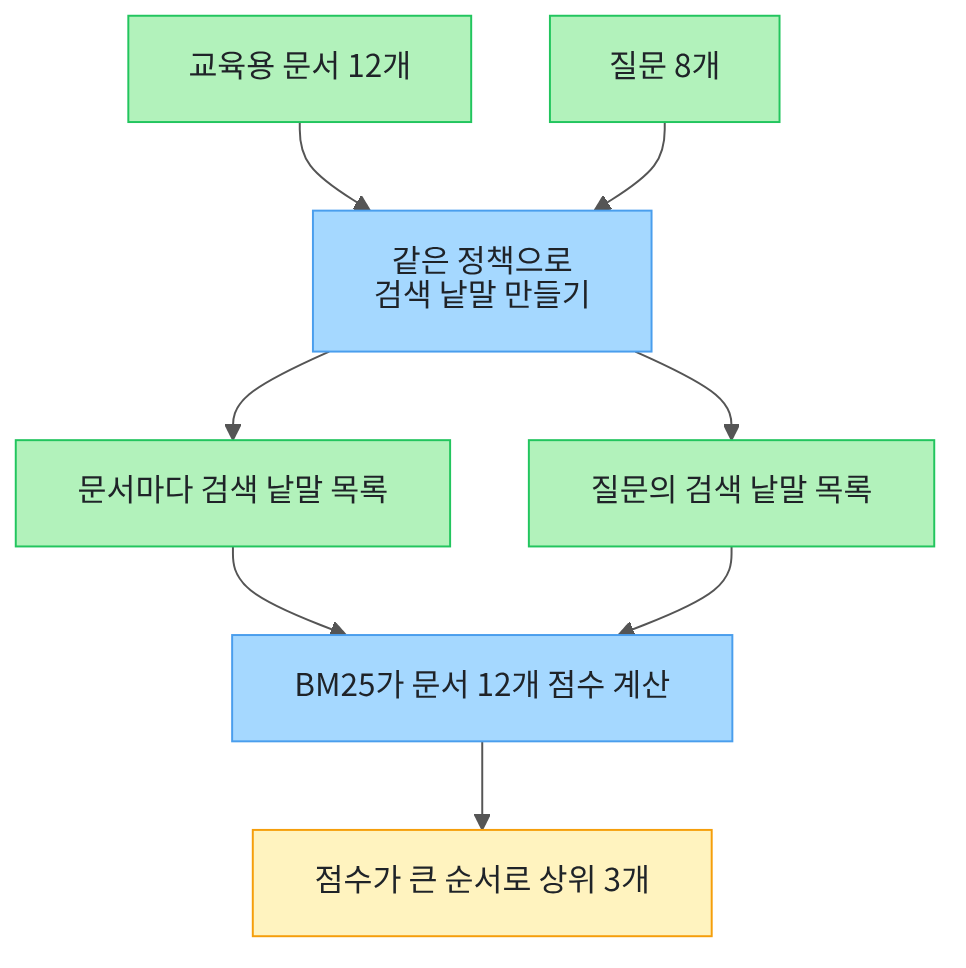

맨 위 초록 상자 두 개가 이 절에서 쓰는 자료입니다.
가운데 파란 상자는 우리가 정한 처리이고 위에서 아래로 읽습니다.
문서와 질문이 같은 정책을 지나는 점이 이 절의 핵심입니다.
맨 아래 노란 상자는 이 노트북의 출력으로 확인한 결과입니다.

## 1. 준비

첫 셀은 패키지 두 개를 설치하고 설치된 버전을 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "kiwipiepy==0.23.2" "rank-bm25==0.2.2"
from importlib.metadata import version

print("kiwipiepy:", version("kiwipiepy"))
print("rank-bm25:", version("rank-bm25"))

Note: you may need to restart the kernel to use updated packages.


kiwipiepy: 0.23.2
rank-bm25: 0.2.2


**결과 읽기** — 설치가 끝나면 `kiwipiepy: 0.23.2`와 `rank-bm25: 0.2.2`가 보입니다.
두 줄이 모두 보이면 다음 셀로 넘어갑니다.
이 노트북의 출력은 2026-09-18에 이 두 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름 네 개를 불러옵니다.

In [2]:
# 자료 파일 읽기·폴더 확인·형태소 분석·낱말 점수에 쓸 이름을 불러옵니다
import json
import os

from kiwipiepy import Kiwi
from rank_bm25 import BM25Okapi

print("불러온 이름:", "json", "os", "Kiwi", "BM25Okapi")

불러온 이름: json os Kiwi BM25Okapi


**결과 읽기** — 출력 줄은 `불러온 이름: json os Kiwi BM25Okapi` 하나입니다.
이름 `Kiwi`는 한국어 문장을 형태소로 나누는 분석기입니다.
이름 `BM25Okapi`는 낱말이 겹치는 정도로 문서 점수를 내는 모델입니다.

다음 셀은 프로젝트 맨 위 폴더를 찾습니다. 01~03절과 같은 코드입니다.

In [3]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part3/ch12-retrieval-tuning/data"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: .


**결과 읽기** — 출력 줄은 `고른 경로: .`입니다. `assert`도 통과했습니다.

다음 셀은 01~03절이 쓴 문서 파일과 질문 파일을 그대로 읽습니다.

In [4]:
# 01~03절과 같은 문서 파일과 질문 파일을 불러옵니다
data_path = root_path + "/labs/part3/ch12-retrieval-tuning/data"
with open(data_path + "/core-documents.json", encoding="utf-8") as file:
    docs = json.loads(file.read())
with open(data_path + "/core-queries.json", encoding="utf-8") as file:
    queries = json.loads(file.read())
print("문서 수:", len(docs))
print("질문 수:", len(queries))

문서 수: 12
질문 수: 8


**결과 읽기** — `문서 수: 12`와 `질문 수: 8`이 보입니다.
01~03절과 같은 교육용 자료입니다.
이 절은 벡터를 만들지 않고 같은 글에서 낱말만 꺼내 씁니다.

## 2. 이 절에서 쓸 값 정하기

먼저 검색에 남길 품사 표시를 정합니다.
품사 표시는 형태소마다 붙는 갈래 이름입니다.
이름 `NNG`는 일반 명사이고 `NNP`는 고유 명사, `NNB`는 의존 명사입니다.
이름 `NR`는 수사이고 `VV`는 동사, `VA`는 형용사, `MAG`는 부사입니다.
이름 `SN`은 숫자이고 `SL`은 영문 낱말입니다.

In [5]:
# 검색에 남길 품사 표시와 받아 올 줄 수, 자르는 자리, 견줄 정책 이름을 정합니다
keep_tags = ["NNG", "NNP", "NNB", "NR", "VV", "VA", "MAG", "SN", "SL"]
top_three = 3
cutoff_values = [1, 2, 3]
policy_names = ["공백 분리", "Kiwi 형태소"]
print("남길 품사 표시:", keep_tags)
print("받아 올 줄 수:", top_three)
print("자르는 자리 세 가지:", cutoff_values)
print("견줄 정책 두 가지:", policy_names)

남길 품사 표시: ['NNG', 'NNP', 'NNB', 'NR', 'VV', 'VA', 'MAG', 'SN', 'SL']
받아 올 줄 수: 3
자르는 자리 세 가지: [1, 2, 3]
견줄 정책 두 가지: ['공백 분리', 'Kiwi 형태소']


**결과 읽기** — 라벨 줄 `남길 품사 표시:` 뒤에 이름 아홉 개가 보입니다.
조사와 어미의 이름은 목록에 없으므로 검색 낱말에서 빠집니다.
출력 줄 `받아 올 줄 수: 3`과 `자르는 자리 세 가지: [1, 2, 3]`은 01~03절과 같은 값입니다.
`견줄 정책 두 가지: ['공백 분리', 'Kiwi 형태소']` 줄의 두 이름으로 뒤에서 기록을 나눕니다.

## 3. 형태소 분석기 써 보기

한국어는 낱말 뒤에 조사와 어미가 붙습니다.
그래서 공백으로만 나누면 같은 말이 서로 다른 낱말이 됩니다.
예로 쓸 한 문장을 두 방법으로 나눠 봅니다.

In [6]:
# 형태소 분석기를 준비하고 예로 쓸 한 문장을 공백으로 나눠 봅니다
kiwi = Kiwi()
sample_text = "예약자가 없으면 일반 도서를 연장할 수 있습니다."
space_words = sample_text.split()
sample_tokens = kiwi.tokenize(sample_text)
print("공백 분리로 만든 검색 낱말 수:", len(space_words))
print("공백 분리로 만든 검색 낱말:", space_words)
print("형태소 수:", len(sample_tokens))

공백 분리로 만든 검색 낱말 수: 7
공백 분리로 만든 검색 낱말: ['예약자가', '없으면', '일반', '도서를', '연장할', '수', '있습니다.']
형태소 수: 15


**결과 읽기** — `공백 분리로 만든 검색 낱말 수: 7`이고 `형태소 수: 15`입니다.
공백으로 나눈 목록에는 `예약자가`와 `도서를`처럼 꼬리가 붙어 있습니다.
형태소는 그 꼬리를 떼어 내므로 수가 더 많습니다.

다음 셀은 형태소마다 붙은 품사 표시를 함께 봅니다.

In [7]:
# 형태소와 품사 표시를 라벨 줄 아래에 한 줄씩 출력합니다
print("형태소 | 품사 표시")
for token in sample_tokens:
    print(token.form, "|", token.tag)

형태소 | 품사 표시
예약 | NNG
자 | XSN
가 | JKS
없 | VA
으면 | EC
일반 | NNG
도서 | NNG
를 | JKO
연장 | NNG
하 | XSV
ᆯ | ETM
수 | NNB
있 | VA
습니다 | EF
. | SF


**결과 읽기** — 라벨 줄 아래 열다섯 줄이 나옵니다.
첫 줄 `예약 | NNG`와 둘째 줄 `자 | XSN`, 셋째 줄 `가 | JKS`를 보면 `예약자가`가 셋으로 갈렸습니다.
이름 `JKS`는 조사이고 `XSN`은 명사 뒤에 붙는 말입니다.
낱말 `예약자`가 한 덩어리로 남지 않는 점도 출력에서 확인합니다.
열째 줄 `하 | XSV`와 열한째 줄 `ᆯ | ETM`은 `연장할`에서 갈린 형태소입니다.

## 4. 검색 낱말 만들기

이제 남길 품사 표시에 든 형태소만 골라 목록으로 만듭니다.
문서와 질문에 같은 함수를 쓰는 것이 이 절의 규칙입니다.
정책이 다르면 같은 말도 서로 다른 낱말이 되어 점수에 보태지지 않습니다.

In [8]:
# 남길 품사 표시에 든 형태소만 골라 검색 낱말 목록을 반환합니다
def kiwi_terms(text):
    terms = []
    for token in kiwi.tokenize(text):
        # 조사와 어미는 품사 표시가 목록에 없어 빠집니다
        if token.tag in keep_tags:
            terms.append(token.form)
    return terms

**결과 읽기** — 정의 셀이라 출력이 없습니다.
빈 목록을 만든 뒤 `for`와 `append`로 채웁니다. Ch 2 03절에서 배운 모양입니다.

다음 셀은 예로 쓴 문장에 그 함수를 적용합니다.

In [9]:
# 예로 쓴 한 문장의 검색 낱말을 만들어 공백 분리 결과와 견줍니다
sample_terms = kiwi_terms(sample_text)
print("Kiwi 형태소로 만든 검색 낱말 수:", len(sample_terms))
print("Kiwi 형태소로 만든 검색 낱말:", sample_terms)

Kiwi 형태소로 만든 검색 낱말 수: 7
Kiwi 형태소로 만든 검색 낱말: ['예약', '없', '일반', '도서', '연장', '수', '있']


**결과 읽기** — `Kiwi 형태소로 만든 검색 낱말 수: 7`이 보입니다.
목록은 `['예약', '없', '일반', '도서', '연장', '수', '있']`입니다.
공백으로 나눈 목록과 수는 같지만 꼬리가 떨어져 있습니다.
낱말 `도서`는 이제 `도서를`이 아니라 `도서`여서 문서의 `도서`와 짝이 맞습니다.

## 5. 문서 12개를 두 정책으로 나누기

문서마다 제목과 본문을 이어 붙여 한 글로 만듭니다.
01~03절이 임베딩에 넘긴 글과 같은 모양입니다.

In [10]:
# 문서 12개의 제목과 본문을 이어 붙이고 문서 ID 목록도 만듭니다(01~03절과 같은 모양)
doc_texts = []
doc_ids = []
for doc in docs:
    doc_texts.append(doc["title"] + " " + doc["text"])
    doc_ids.append(doc["doc_id"])
print("이어 붙인 글 수:", len(doc_texts))
print("첫 문서 ID:", doc_ids[0])
print("첫 문서 글:", doc_texts[0])

이어 붙인 글 수: 12
첫 문서 ID: LIB-001
첫 문서 글: 도서 대출 기간 일반 도서는 14일 동안 대출할 수 있습니다. 예약자가 없으면 한 번 연장할 수 있습니다.


**결과 읽기** — `이어 붙인 글 수: 12`와 `첫 문서 ID: LIB-001`이 보입니다.
`첫 문서 글:` 줄에는 제목 `도서 대출 기간`과 본문이 이어져 있습니다.

다음 셀은 그 글 열두 개를 두 정책으로 각각 나눕니다.

In [11]:
# 문서마다 두 정책으로 검색 낱말 목록을 만들어 두 벌을 준비합니다
kiwi_corpus = []
space_corpus = []
for text in doc_texts:
    kiwi_corpus.append(kiwi_terms(text))
    space_corpus.append(text.split())
print("Kiwi 형태소 목록 수:", len(kiwi_corpus))
print("공백 분리 목록 수:", len(space_corpus))

Kiwi 형태소 목록 수: 12
공백 분리 목록 수: 12


**결과 읽기** — `Kiwi 형태소 목록 수: 12`와 `공백 분리 목록 수: 12`가 보입니다.
목록 하나가 문서 한 건의 검색 낱말 목록입니다.
순위 함수에 넘기는 재료는 글이 아니라 이런 목록의 목록입니다.

다음 셀은 문서마다 검색 낱말이 몇 개인지 셉니다.

In [12]:
# 문서마다 검색 낱말이 몇 개인지 라벨 줄 아래에 출력합니다
print("문서 ID | Kiwi 형태소 | 공백 분리")
for i in range(len(doc_ids)):
    print(doc_ids[i], "|", len(kiwi_corpus[i]), "|", len(space_corpus[i]))

문서 ID | Kiwi 형태소 | 공백 분리
LIB-001 | 17 | 17
LIB-002 | 12 | 14
LIB-003 | 14 | 15
LIB-004 | 15 | 14
FAC-001 | 21 | 17
FAC-002 | 16 | 14
FAC-003 | 16 | 14
FAC-004 | 14 | 13
ACC-001 | 14 | 13
ACC-002 | 16 | 15
ACC-003 | 15 | 15
ACC-004 | 14 | 15


**결과 읽기** — 라벨 줄 아래 열두 줄이 나옵니다.
첫 줄은 `LIB-001 | 17 | 17`이고 다섯째 줄은 `FAC-001 | 21 | 17`입니다.
문서마다 낱말 수가 다르고 두 정책의 수도 문서에 따라 다릅니다.
순위 함수 BM25는 이 낱말 수를 문서 길이로 씁니다.

## 6. BM25 모델 만들기

이제 두 벌의 목록으로 모델을 각각 만듭니다.
모델은 낱말마다 「문서 12개 가운데 몇 건에 있는가」와 문서 길이를 미리 셉니다.
정책 이름을 키로 둔 딕셔너리에 담아 두면 함수 하나로 두 정책을 견줄 수 있습니다.

In [13]:
# 두 벌의 낱말 목록으로 BM25 모델을 각각 만들고 정책 이름을 붙여 담습니다
space_bm25 = BM25Okapi(space_corpus)
kiwi_bm25 = BM25Okapi(kiwi_corpus)
bm25_models = {policy_names[0]: space_bm25, policy_names[1]: kiwi_bm25}
print("만든 모델 수:", len(bm25_models))
print("Kiwi 모델이 본 문서 수:", kiwi_bm25.corpus_size)
print("문서 하나의 평균 검색 낱말 수:", round(kiwi_bm25.avgdl, 2))

만든 모델 수: 2
Kiwi 모델이 본 문서 수: 12
문서 하나의 평균 검색 낱말 수: 15.33


**결과 읽기** — `만든 모델 수: 2`와 `Kiwi 모델이 본 문서 수: 12`가 보입니다.
출력 줄 `문서 하나의 평균 검색 낱말 수: 15.33`은 열두 문서 낱말 수의 평균입니다.
순위 함수 BM25는 이 평균보다 긴 문서의 점수를 조금 낮춥니다.

## 7. 드문 낱말 세어 보기

BM25 점수는 질문 낱말이 드물수록 커집니다.
드문 정도는 「그 낱말이 있는 문서가 몇 건인가」로 셉니다.
문서 한 건에만 있는 낱말은 그 문서를 가리키는 힘이 셉니다.

In [14]:
# 낱말 하나가 문서 12개 가운데 몇 건의 검색 낱말 목록에 있는지 셉니다
def count_docs_with(term):
    found_count = 0
    for terms in kiwi_corpus:
        if term in terms:
            found_count = found_count + 1
    return found_count

**결과 읽기** — 정의 셀이라 출력이 없습니다.
낱말이 목록에 몇 번 나오는지가 아니라 몇 건의 문서에 있는지를 셉니다.

다음 셀은 낱말이 중요한 질문 하나를 골라 그 낱말들을 세어 봅니다.

In [15]:
# 낱말이 중요한 질문 하나를 골라 그 검색 낱말이 몇 건의 문서에 있는지 봅니다
keyword_query = queries[2]
keyword_terms = kiwi_terms(keyword_query["question"])
print("고른 질문:", keyword_query["qid"], "|", keyword_query["question"])
print("그 질문의 정답 문서 ID:", keyword_query["gold_doc_id"])
print("질문의 검색 낱말:", keyword_terms)
print("낱말 | 그 낱말이 있는 문서 수")
for term in keyword_terms:
    print(term, "|", count_docs_with(term))

고른 질문: C03 | ISBN으로 없는 책을 신청하려면?
그 질문의 정답 문서 ID: LIB-003
질문의 검색 낱말: ['ISBN', '없', '책', '신청']
낱말 | 그 낱말이 있는 문서 수
ISBN | 1
없 | 2
책 | 2
신청 | 2


**결과 읽기** — `고른 질문: C03 | ISBN으로 없는 책을 신청하려면?`이 보입니다.
`그 질문의 정답 문서 ID: LIB-003`이고 검색 낱말은 `['ISBN', '없', '책', '신청']`입니다.
라벨 줄 아래 네 줄에서 `ISBN | 1`과 `신청 | 2`가 보입니다.
낱말 `ISBN`은 문서 열두 건 가운데 한 건에만 있습니다.
나머지 세 낱말은 두 건씩에 있어 가리키는 힘이 약합니다.

## 8. 순위 함수 만들기

먼저 정책 이름에 맞는 방법으로 검색 낱말을 만드는 함수를 둡니다.
이 함수 하나로 질문 쪽 정책과 문서 쪽 정책을 같게 맞춥니다.

In [16]:
# 정책 이름에 맞는 방법으로 글 하나에서 검색 낱말 목록을 만듭니다
def terms_by_policy(policy_name, text):
    if policy_name == policy_names[0]:
        return text.split()
    return kiwi_terms(text)

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 점수를 내고 순위를 만드는 함수입니다.
01·03절은 거리를 `sorted()`로 정렬해 작은 값을 앞에 두었습니다.
BM25 점수는 클수록 관련 있으므로 방향이 반대입니다.
그래서 점수에 음수를 붙여 담고 `sorted()`로 정렬합니다.

In [17]:
# 질문 하나를 한 정책으로 재어 점수가 큰 순서로 문서 ID와 점수 목록을 반환합니다
def rank_by_bm25(policy_name, question, top_count):
    question_terms = terms_by_policy(policy_name, question)
    scores = bm25_models[policy_name].get_scores(question_terms)
    pairs = []
    for i in range(len(doc_ids)):
        # 점수에 음수를 붙이면 sorted가 큰 점수를 앞으로 보냅니다
        pairs.append((0 - scores[i], doc_ids[i]))
    hit_list = []
    for pair in sorted(pairs):
        hit_list.append({"doc_id": pair[1], "점수": round(0 - pair[0], 2)})
    return hit_list[:top_count]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
튜플의 첫 칸이 음수 점수이고 둘째 칸이 문서 ID입니다.
꺼낼 때 다시 음수를 붙이면 원래 점수가 됩니다.
점수가 같은 문서끼리는 문서 ID 차례로 놓입니다.

다음 셀은 순위 목록을 표 모양으로 출력하는 함수입니다.
02·03절 `print_hits()`는 칸 이름이 `거리`라 이름을 갈랐습니다.

In [18]:
# 순위 목록을 순위·문서 ID·BM25 점수 세 칸으로 출력합니다
def print_scores(hit_list):
    print("순위 | 문서 ID | BM25 점수")
    for rank_number in range(len(hit_list)):
        row = hit_list[rank_number]
        print(rank_number + 1, "|", row["doc_id"], "|", row["점수"])

**결과 읽기** — 정의 셀이라 출력이 없습니다.

## 9. 실행 1 — Kiwi 형태소로 검색

실행 전에 예상해 봅니다.
낱말 `ISBN`이 한 건에만 있으니 그 문서가 1위일 것입니다.

In [19]:
# 실행 1: Kiwi 형태소 정책으로 고른 질문의 상위 세 문서를 받아 옵니다
kiwi_hits = rank_by_bm25(policy_names[1], keyword_query["question"], top_three)
print("쓴 정책:", policy_names[1])
print_scores(kiwi_hits)

쓴 정책: Kiwi 형태소
순위 | 문서 ID | BM25 점수
1 | LIB-003 | 6.34
2 | ACC-003 | 1.45
3 | LIB-004 | 1.45


**결과 읽기** — `쓴 정책: Kiwi 형태소`이고 라벨 줄 아래 첫 줄은 `1 | LIB-003 | 6.34`입니다.
정답 문서가 1위이고 점수가 둘째 줄보다 네 배 넘게 큽니다.
둘째와 셋째 줄은 점수가 같은 `1.45`입니다.
점수가 같으면 순서는 BM25가 아니라 문서 ID 차례가 정합니다.

## 10. 값 바꿔 보기 — 공백 분리로 검색

바꿀 값은 정책 이름 하나입니다.
`Kiwi 형태소`에서 `공백 분리`로 바꿉니다.
질문과 문서, 받아 올 줄 수는 그대로 둡니다.
실행 전에 예상해 봅니다. 질문 낱말에 꼬리가 붙어 겹치는 낱말이 없을 것입니다.

In [20]:
# 값 바꿔 보기: 정책 이름만 공백 분리로 바꿔 같은 질문을 다시 잽니다
space_hits = rank_by_bm25(policy_names[0], keyword_query["question"], top_three)
print("쓴 정책:", policy_names[0])
print("이 정책이 본 질문 낱말:", keyword_query["question"].split())
print_scores(space_hits)

쓴 정책: 공백 분리
이 정책이 본 질문 낱말: ['ISBN으로', '없는', '책을', '신청하려면?']
순위 | 문서 ID | BM25 점수
1 | ACC-001 | 0.0
2 | ACC-002 | 0.0
3 | ACC-003 | 0.0


**결과 읽기** — `이 정책이 본 질문 낱말: ['ISBN으로', '없는', '책을', '신청하려면?']`이 보입니다.
라벨 줄 아래 세 줄의 점수가 모두 `0.0`입니다.
문서 어디에도 `ISBN으로`라는 낱말이 없기 때문입니다.
점수가 모두 같으므로 위에 놓인 세 문서는 문서 ID 차례로 정해졌습니다.
`1 | ACC-001 | 0.0` 줄의 문서는 질문과 낱말이 겹쳐서 올라온 것이 아닙니다.

## 11. 질문 여덟 개를 잴 함수 준비

질문 하나로는 두 정책의 차이를 말할 수 없습니다.
Ch 11과 01~03절에서 쓴 지표 함수 네 개를 그대로 이어 씁니다.

In [21]:
# 순위 목록에서 문서 ID를 차례로 모으고 처음 나온 것만 남깁니다(Ch 11 01절과 같은 코드)
def unique_doc_ids(hit_list):
    doc_ids = []
    for hit in hit_list:
        if hit["doc_id"] not in doc_ids:
            doc_ids.append(hit["doc_id"])
    return doc_ids

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 함수가 보는 키는 `doc_id` 하나여서 칸 이름이 `점수`여도 그대로 씁니다.

정답 자리는 고유 문서 목록에서 정답 문서가 몇 번째인지 센 값입니다.

In [22]:
# 고유 문서 목록에서 정답 문서 ID가 몇 번째 자리인지 찾습니다(Ch 11 01절과 같은 코드)
def find_gold_rank(doc_ids, gold_doc_ids):
    gold_rank = 0
    for position in range(len(doc_ids)):
        if doc_ids[position] in gold_doc_ids:
            gold_rank = position + 1
            break
    return gold_rank

**결과 읽기** — 정의 셀이라 출력이 없습니다.

재현율은 자르는 자리까지 자른 목록에 정답 문서가 들어온 비율입니다.

In [23]:
# 고유 문서 목록을 자르는 자리에서 자르고 정답 문서가 들어온 비율을 냅니다(Ch 11 02절과 같은 코드)
def recall_at(doc_ids, gold_doc_ids, cutoff):
    top_ids = doc_ids[:cutoff]
    found_count = 0
    for gold_id in gold_doc_ids:
        if gold_id in top_ids:
            found_count = found_count + 1
    return found_count / len(gold_doc_ids)

**결과 읽기** — 정의 셀이라 출력이 없습니다.

질문마다 낸 점수를 같은 무게로 평균하는 함수입니다.

In [24]:
# 질문마다 낸 점수를 같은 무게로 평균해 소수 셋째 자리까지 남깁니다(Ch 11 02절과 같은 코드)
def mean_score(score_list):
    total = 0
    for score in score_list:
        total = total + score
    return round(total / len(score_list), 3)

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 질문 하나를 한 정책으로 재어 기록 한 줄을 만듭니다.
1위 점수를 칸으로 둔 점이 03절 기록과 다릅니다.

In [25]:
# 질문 하나를 한 정책으로 재어 기록 한 줄을 만듭니다
def score_one(query_index, policy_name):
    query = queries[query_index]
    gold_doc_ids = [query["gold_doc_id"]]
    hit_list = rank_by_bm25(policy_name, query["question"], top_three)
    found_ids = unique_doc_ids(hit_list)
    row = {"정책": policy_name, "질문": query["qid"]}
    row["1위 점수"] = hit_list[0]["점수"]
    row["정답 자리"] = find_gold_rank(found_ids, gold_doc_ids)
    for cutoff in cutoff_values:
        row["자리 " + str(cutoff)] = recall_at(found_ids, gold_doc_ids, cutoff)
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.

## 12. 두 정책의 재현율 견주기

질문 여덟 개를 두 정책으로 모두 잽니다.
모델을 미리 만들어 두었으므로 새로 세는 일은 없습니다.

In [26]:
# 질문 여덟 개를 두 정책으로 모두 재어 기록 줄을 담습니다
score_rows = []
for policy_name in policy_names:
    for query_index in range(len(queries)):
        score_rows.append(score_one(query_index, policy_name))
print("담은 기록 줄 수:", len(score_rows))

담은 기록 줄 수: 16


**결과 읽기** — `담은 기록 줄 수: 16`이 보입니다. 질문 여덟 개에 정책 두 가지를 곱한 수입니다.

다음 셀은 담은 줄을 표로 출력합니다.

In [27]:
# 정책·질문·1위 점수·정답 자리·자리 1·자리 3을 라벨 줄 아래에 차례로 출력합니다
print("정책 | 질문 | 1위 점수 | 정답 자리 | 자리 1 재현율 | 자리 3 재현율")
for row in score_rows:
    print(row["정책"], "|", row["질문"], "|", row["1위 점수"], "|", row["정답 자리"], "|", row["자리 1"], "|", row["자리 3"])

정책 | 질문 | 1위 점수 | 정답 자리 | 자리 1 재현율 | 자리 3 재현율
공백 분리 | C01 | 2.58 | 2 | 0.0 | 1.0
공백 분리 | C02 | 0.0 | 0 | 0.0 | 0.0
공백 분리 | C03 | 0.0 | 0 | 0.0 | 0.0
공백 분리 | C04 | 1.9 | 1 | 1.0 | 1.0
공백 분리 | C05 | 0.0 | 0 | 0.0 | 0.0
공백 분리 | C06 | 3.02 | 1 | 1.0 | 1.0
공백 분리 | C07 | 2.5 | 1 | 1.0 | 1.0
공백 분리 | C08 | 0.0 | 3 | 0.0 | 1.0
Kiwi 형태소 | C01 | 3.37 | 3 | 0.0 | 1.0
Kiwi 형태소 | C02 | 2.26 | 1 | 1.0 | 1.0
Kiwi 형태소 | C03 | 6.34 | 1 | 1.0 | 1.0
Kiwi 형태소 | C04 | 8.18 | 1 | 1.0 | 1.0
Kiwi 형태소 | C05 | 3.41 | 1 | 1.0 | 1.0
Kiwi 형태소 | C06 | 2.99 | 1 | 1.0 | 1.0
Kiwi 형태소 | C07 | 8.73 | 1 | 1.0 | 1.0
Kiwi 형태소 | C08 | 4.99 | 1 | 1.0 | 1.0


**결과 읽기** — 라벨 줄 아래 앞 여덟 줄이 공백 분리입니다.
그 가운데 네 줄의 1위 점수가 `0.0`이고 세 줄은 정답 자리가 `0`입니다.
줄 `공백 분리 | C08 | 0.0 | 3`은 점수가 모두 같아 정해진 자리입니다.
뒤 여덟 줄은 Kiwi 형태소이고 일곱 질문의 정답 자리가 `1`입니다.
줄 `Kiwi 형태소 | C01 | 3.37 | 3`은 정답 문서가 셋째 자리였던 질문입니다.

다음 셀은 자르는 자리마다 질문 평균 재현율을 견줍니다.

In [28]:
# 두 정책의 질문 평균 재현율을 자르는 자리마다 견줍니다
print("정책 | 자르는 자리 | 질문 평균 재현율")
for policy_name in policy_names:
    picked = []
    for row in score_rows:
        if row["정책"] == policy_name:
            picked.append(row)
    for cutoff in cutoff_values:
        scores = []
        for row in picked:
            scores.append(row["자리 " + str(cutoff)])
        print(policy_name, "|", cutoff, "|", mean_score(scores))

정책 | 자르는 자리 | 질문 평균 재현율
공백 분리 | 1 | 0.375
공백 분리 | 2 | 0.5
공백 분리 | 3 | 0.625
Kiwi 형태소 | 1 | 0.875
Kiwi 형태소 | 2 | 0.875
Kiwi 형태소 | 3 | 1.0


**결과 읽기** — 라벨 줄 아래 여섯 줄이 나옵니다.
공백 분리는 자리 1에서 `0.375`, 자리 3에서 `0.625`입니다.
Kiwi 형태소는 자리 1에서 `0.875`, 자리 3에서 `1.0`입니다.
자리 3 값 `1.0`은 여덟 질문 모두 정답 문서가 상위 세 자리에 들어왔다는 뜻입니다.

## 정리

1. 공백으로만 나누면 꼬리가 붙어 같은 말이 서로 다른 낱말이 되었습니다.
2. 낱말 `ISBN`은 문서 한 건에만 있어 그 문서 점수가 `6.34`로 크게 나왔습니다.
3. 질문 여덟 개 질문 평균 재현율은 자리 3에서 공백 분리 `0.625`, Kiwi 형태소 `1.0`이었습니다.

05절에서는 같은 질문 여덟 개에서 벡터 거리 검색과 낱말 겹침 검색의 결과를 나란히 놓습니다.
두 검색이 서로 다른 문서를 고르는 자리를 찾습니다.